In [ ]:
# ==========================================
# SUPPLEMENTARY ANALYSIS: HYPERPARAMETER TUNING
# ==========================================
# Objective: Investigate the impact of hyperparameter optimization
# on classical baselines (LR) and deep learning models (FNN).
# Input: CSV Dataset (Generated from Shadow Tomography)
# ==========================================

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from tqdm.auto import tqdm
import warnings
import io

# Suppress warnings
warnings.filterwarnings("ignore")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# -----------------------------------------------------------------------------
# 1. DATA LOADING
# -----------------------------------------------------------------------------
print("\n--- Step 1: Data Setup ---")
try:
    # Try local load first
    df = pd.read_csv('../data/quantum_shadow_dataset.csv')
    print("Local file found.")
except FileNotFoundError:
    # Fallback to upload
    try:
        from google.colab import files
        print("File not found. Please upload 'quantum_shadow_dataset.csv':")
        uploaded = files.upload()
        filename = next(iter(uploaded))
        df = pd.read_csv(io.BytesIO(uploaded[filename]))
    except:
        raise ImportError("Could not load data. Ensure CSV is generated.")

X = df.drop(columns=['label']).values
y = df['label'].values

# Split (Random state removed for stochasticity)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y
)
print(f"Train Size: {len(X_train)} | Test Size: {len(X_test)}")


--- Step 2: Logistic Regression Tuning ---
Baseline LR: 0.8065
Tuned LR:    0.8451 (Best C=0.01)

--- Step 3: FNN Tuning (5-Fold CV) ---
Baseline FNN: 0.8060


FNN CV Tuning:   0%|          | 0/60 [00:00<?, ?it/s]

Best Config Found: {'hidden': 32, 'dropout': 0.5, 'lr': 0.001}
Tuned FNN:    0.8657


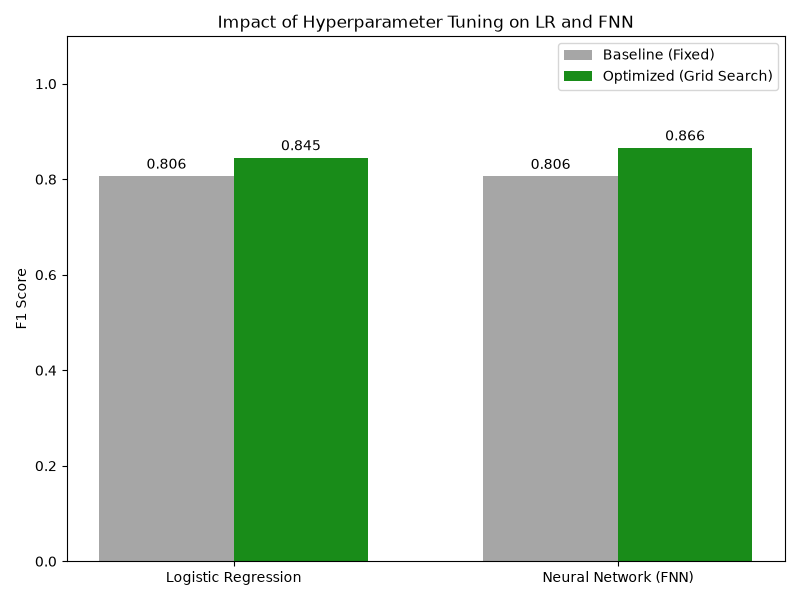

In [4]:
# -----------------------------------------------------------------------------
# 2. LOGISTIC REGRESSION (Grid Search CV)
# -----------------------------------------------------------------------------
print("\n--- Step 2: Logistic Regression Tuning ---")

# Baseline (Default)
lr_base = LogisticRegression(max_iter=1000, class_weight='balanced')
lr_base.fit(X_train, y_train)
base_lr_score = f1_score(y_test, lr_base.predict(X_test))

# Tuning
lr_params = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs']
}
lr_grid = GridSearchCV(LogisticRegression(max_iter=5000, class_weight='balanced'),
                       lr_params, cv=5, scoring='f1', n_jobs=-1)
lr_grid.fit(X_train, y_train)

best_lr = lr_grid.best_estimator_
tuned_lr_score = f1_score(y_test, best_lr.predict(X_test))

print(f"Baseline LR: {base_lr_score:.4f}")
print(f"Tuned LR:    {tuned_lr_score:.4f} (Best C={lr_grid.best_params_['C']})")

# -----------------------------------------------------------------------------
# 3. NEURAL NETWORK (Manual Cross-Validation)
# -----------------------------------------------------------------------------
print("\n--- Step 3: FNN Tuning (5-Fold CV) ---")

class TunableFNN(nn.Module):
    def __init__(self, input_dim, hidden, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2), nn.ReLU(),
            nn.Linear(hidden // 2, 1), nn.Sigmoid()
        )
    def forward(self, x): return self.net(x)

# Baseline Config (Fixed from main report)
# We just train it once on full X_train to get the baseline score
base_fnn = TunableFNN(16, 64, 0.4).to(device)
opt = optim.Adam(base_fnn.parameters(), lr=0.001)
crit = nn.BCELoss()

t_X_tr = torch.tensor(X_train, dtype=torch.float32).to(device)
t_y_tr = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1).to(device)
t_X_te = torch.tensor(X_test, dtype=torch.float32).to(device)

base_fnn.train()
for _ in range(300):
    opt.zero_grad()
    crit(base_fnn(t_X_tr), t_y_tr).backward()
    opt.step()

with torch.no_grad():
    base_fnn_score = f1_score(y_test, (base_fnn(t_X_te)>0.5).cpu().numpy().astype(int))
print(f"Baseline FNN: {base_fnn_score:.4f}")

# --- Grid Search Loop with Cross-Validation ---
fnn_grid = {
    'hidden': [32, 64, 128],
    'dropout': [0.2, 0.5],
    'lr': [0.01, 0.001]
}

best_cv_score = 0
best_config = {}

# Iterate over all hyperparameter combinations
total_runs = len(fnn_grid['hidden']) * len(fnn_grid['dropout']) * len(fnn_grid['lr']) * 5 # 5 folds
pbar = tqdm(total=total_runs, desc="FNN CV Tuning")

for h in fnn_grid['hidden']:
    for d in fnn_grid['dropout']:
        for lr in fnn_grid['lr']:

            # 5-Fold CV for this specific config
            kfold = StratifiedKFold(n_splits=5, shuffle=True)
            fold_scores = []

            for train_idx, val_idx in kfold.split(X_train, y_train):
                # Data Prep for Fold
                X_fold_t = torch.tensor(X_train[train_idx], dtype=torch.float32).to(device)
                y_fold_t = torch.tensor(y_train[train_idx], dtype=torch.float32).unsqueeze(1).to(device)
                X_fold_v = torch.tensor(X_train[val_idx], dtype=torch.float32).to(device)
                y_fold_v = y_train[val_idx] # Keep as numpy for metric calc

                # Train Model
                model = TunableFNN(16, h, d).to(device)
                optimizer = optim.Adam(model.parameters(), lr=lr)

                model.train()
                for _ in range(200): # Fast epochs
                    optimizer.zero_grad()
                    loss = crit(model(X_fold_t), y_fold_t)
                    loss.backward()
                    optimizer.step()

                # Evaluate on Validation Fold
                model.eval()
                with torch.no_grad():
                    preds = (model(X_fold_v) > 0.5).cpu().numpy().astype(int)
                fold_scores.append(f1_score(y_fold_v, preds))
                pbar.update(1)

            # Check if this config is the winner
            avg_score = np.mean(fold_scores)
            if avg_score > best_cv_score:
                best_cv_score = avg_score
                best_config = {'hidden': h, 'dropout': d, 'lr': lr}

pbar.close()

# Retrain BEST model on full X_train and evaluate on X_test
print(f"Best Config Found: {best_config}")
final_model = TunableFNN(16, best_config['hidden'], best_config['dropout']).to(device)
opt = optim.Adam(final_model.parameters(), lr=best_config['lr'])

final_model.train()
for _ in range(300):
    opt.zero_grad()
    crit(final_model(t_X_tr), t_y_tr).backward()
    opt.step()

with torch.no_grad():
    tuned_fnn_score = f1_score(y_test, (final_model(t_X_te)>0.5).cpu().numpy().astype(int))

print(f"Tuned FNN:    {tuned_fnn_score:.4f}")

# -----------------------------------------------------------------------------
# 4. VISUALIZATION
# -----------------------------------------------------------------------------
methods = ['Logistic Regression', 'Neural Network (FNN)']
base_scores = [base_lr_score, base_fnn_score]
tuned_scores = [tuned_lr_score, tuned_fnn_score]

x = np.arange(len(methods))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
rects1 = ax.bar(x - width/2, base_scores, width, label='Baseline (Fixed)', color='gray', alpha=0.7)
rects2 = ax.bar(x + width/2, tuned_scores, width, label='Optimized (Grid Search)', color='green', alpha=0.9)

ax.set_ylabel('F1 Score')
ax.set_title('Impact of Hyperparameter Tuning on LR and FNN')
ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylim(0, 1.1)
ax.legend()

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)
plt.savefig('../figures/hyperparameter_tuning.png', dpi=250)
plt.show()